(1) Uji peforma model pada epoch 5 melalui data validasi

In [2]:
# Import library & konfigurasi dataset
from pathlib import Path
import xml.etree.ElementTree as ET

import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision.transforms.functional import to_tensor

# Lokasi dataset
ROOT = Path(r"C:\Faster-RCNN-PPE\dataset\images")

# Pemetaan kelas
CLASS_MAP = {
    "person": 1,
    "vest": 2,
    "yellow": 3,
    "white": 4,
    "glass": 5,
    "blue": 6,
    "red": 7,
    "head": 8
}

In [8]:
# Membuat Dataset class Faster R-CNN
from pathlib import Path
import xml.etree.ElementTree as ET

import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision.transforms.functional import to_tensor

# Lokasi dataset
ROOT = Path(r"C:\Faster-RCNN-PPE\dataset\images")

# Pemetaan kelas XML ke ID Faster R-CNN
CLASS_MAP = {
    "person": 1,
    "vest": 2,
    "yellow": 3,
    "white": 4,
    "glass": 5,
    "blue": 6,
    "red": 7,
    "head": 8
}

class CHVGPpeDataset(Dataset):

    def __init__(self, root, split):
        self.folder = Path(root) / split

        self.images = sorted([
            f for f in self.folder.iterdir()
            if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg"]
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = self.images[idx]
        xml_path = self.folder / (image_path.stem + ".xml")

        # Baca gambar
        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        # Baca XML
        root = ET.parse(xml_path).getroot()

        boxes = []
        labels = []

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if class_name not in CLASS_MAP:
                raise ValueError(
                    f"Kelas tidak dikenal: {class_name}"
                )

            bbox = obj.find("bndbox")

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            # Clipping koordinat ke batas gambar
            xmin = max(0, min(xmin, width))
            ymin = max(0, min(ymin, height))
            xmax = max(0, min(xmax, width))
            ymax = max(0, min(ymax, height))

            # Abaikan box yang menjadi tidak valid setelah clipping
            if xmin >= xmax or ymin >= ymax:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(CLASS_MAP[class_name])

        # Konversi gambar menjadi tensor
        image_tensor = to_tensor(image)

        # Tensor anotasi
        boxes_tensor = torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4)

        labels_tensor = torch.tensor(
            labels, dtype=torch.int64
        )

        target = {
            "boxes": boxes_tensor,
            "labels": labels_tensor,
            "image_id": torch.tensor([idx]),
            "area": (
                (boxes_tensor[:, 2] - boxes_tensor[:, 0]) *
                (boxes_tensor[:, 3] - boxes_tensor[:, 1])
            ),
            "iscrowd": torch.zeros(
                (len(labels),), dtype=torch.int64
            )
        }

        return image_tensor, target


# Membuat dataset untuk setiap split
train_dataset = CHVGPpeDataset(ROOT, "train")
val_dataset = CHVGPpeDataset(ROOT, "val")
test_dataset = CHVGPpeDataset(ROOT, "test")

print("Dataset berhasil dibuat")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Dataset berhasil dibuat
Train: 1189
Validation: 170
Test: 340


In [9]:
# Membuat Data Loader
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

# DataLoader Validation
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

# DataLoader Test
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

print("=== DATALOADER BERHASIL DIBUAT ===")
print("Validation batches:", len(val_loader))
print("Test batches      :", len(test_loader))

=== DATALOADER BERHASIL DIBUAT ===
Validation batches: 170
Test batches      : 340


In [4]:
# Inisialisasi DirectML dan arsitektur model
import torch
import torch_directml
import os

from torchvision.models.detection import fasterrcnn_resnet50_fpn

# 1. Inisialisasi DirectML
device = torch_directml.device()

print("Device:", device)
print("Nama GPU:", torch_directml.device_name(0))

# 2. Membuat arsitektur Faster R-CNN
model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=9,
    min_size=640,
    max_size=640
)

model.to(device)

print("Arsitektur Faster R-CNN berhasil dibuat.")

Device: privateuseone:0
Nama GPU: AMD Radeon (TM) Graphics 
Arsitektur Faster R-CNN berhasil dibuat.


In [6]:
# Memuat checkpoint epoch 5
import os

checkpoint_path = r"C:\Faster-RCNN-PPE\experiments\fasterrcnn_20_epochs\fasterrcnn_epoch_5.pth"

assert os.path.exists(checkpoint_path), "Checkpoint tidak ditemukan!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("=== CHECKPOINT EPOCH 5 BERHASIL DIMUAT ===")
print("Epoch training :", checkpoint["epoch"])
print("Average loss   :", checkpoint["average_epoch_loss"])
print("Total loss     :", checkpoint["total_epoch_loss"])
print("Jumlah kelas   :", checkpoint["num_classes"])
print("Device         :", device)

=== CHECKPOINT EPOCH 5 BERHASIL DIMUAT ===
Epoch training : 5
Average loss   : 0.2913662218234186
Total loss     : 346.43443774804473
Jumlah kelas   : 9
Device         : privateuseone:0


In [7]:
# Menyiapkan konfigurasi pengujian
CONF_THRESHOLD = 0.40
IOU_THRESHOLD = 0.50

print("=== KONFIGURASI PENGUJIAN ===")
print("Confidence threshold :", CONF_THRESHOLD)
print("IoU matching threshold :", IOU_THRESHOLD)
print("Jumlah gambar validasi :", len(val_dataset))

=== KONFIGURASI PENGUJIAN ===
Confidence threshold : 0.4
IoU matching threshold : 0.5
Jumlah gambar validasi : 170


In [8]:
# Cek kesiapan model untuk dievaluasi
model.eval()

print("Model dalam mode evaluasi:", not model.training)
print("Device:", device)

Model dalam mode evaluasi: True
Device: privateuseone:0


In [9]:
# Coba uji 5 gambar untuk memastikan RAM aman
model.eval()

with torch.no_grad():
    for i, (images, targets) in enumerate(val_loader):

        images = [img.to(device) for img in images]
        predictions = model(images)

        print(f"Gambar ke-{i+1} berhasil diproses")

        if i == 4:
            break

Gambar ke-1 berhasil diproses
Gambar ke-2 berhasil diproses
Gambar ke-3 berhasil diproses
Gambar ke-4 berhasil diproses
Gambar ke-5 berhasil diproses


In [10]:
import gc

del predictions
del images
gc.collect()

9

In [12]:
# Fungsi boix_iou
from torchvision.ops import box_iou

print("Fungsi box_iou berhasil diimpor")

Fungsi box_iou berhasil diimpor


In [14]:
# Inisialisasi perhitungan
TP = 0
FP = 0
FN = 0

CONF_THRESHOLD = 0.40
IOU_THRESHOLD = 0.50

print("TP, FP, FN berhasil diinisialisasi")

TP, FP, FN berhasil diinisialisasi


In [15]:
# Inference & menghitung TP, FP, FN
model.eval()

with torch.no_grad():

    for images, targets in val_loader:

        # Inference satu gambar
        images = [img.to(device) for img in images]
        predictions = model(images)

        # Mengambil hasil prediksi
        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        # Mengambil ground truth
        target = targets[0]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Filter berdasarkan confidence
        keep = pred_scores >= CONF_THRESHOLD

        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        # Urutkan berdasarkan confidence tertinggi
        order = torch.argsort(pred_scores, descending=True)

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):

            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            # Ground truth yang belum dipasangkan dan kelasnya sama
            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]

            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        # Menghapus prediksi sementara setiap gambar
        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

In [16]:
# Menghitung metrik evaluasi
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("=== HASIL PENGUJIAN FASTER R-CNN EPOCH 5 ===")
print("Confidence threshold :", CONF_THRESHOLD)
print("IoU threshold        :", IOU_THRESHOLD)
print("TP                   :", TP)
print("FP                   :", FP)
print("FN                   :", FN)
print("Precision            : {:.2f}%".format(precision * 100))
print("Recall               : {:.2f}%".format(recall * 100))
print("F1-Score             : {:.2f}%".format(f1_score * 100))

=== HASIL PENGUJIAN FASTER R-CNN EPOCH 5 ===
Confidence threshold : 0.4
IoU threshold        : 0.5
TP                   : 1108
FP                   : 247
FN                   : 103
Precision            : 81.77%
Recall               : 91.49%
F1-Score             : 86.36%


(2) Uji peforma model pada epoch 10 melalui data validasi

In [5]:
# Muat checkpoint epoch 10
import os

checkpoint_path = r"C:\Faster-RCNN-PPE\experiments\fasterrcnn_20_epochs\fasterrcnn_epoch_10.pth"

assert os.path.exists(checkpoint_path), "Checkpoint tidak ditemukan!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("=== CHECKPOINT EPOCH 10 BERHASIL DIMUAT ===")
print("Epoch training :", checkpoint["epoch"])
print("Average loss   :", checkpoint["average_epoch_loss"])
print("Total loss     :", checkpoint["total_epoch_loss"])
print("Jumlah kelas   :", checkpoint["num_classes"])
print("Device         :", device)

=== CHECKPOINT EPOCH 10 BERHASIL DIMUAT ===
Epoch training : 10
Average loss   : 0.19837502819071606
Total loss     : 235.8679085187614
Jumlah kelas   : 9
Device         : privateuseone:0


In [10]:
# Mengatur ulang menghitung metrik
from torchvision.ops import box_iou

CONF_THRESHOLD = 0.40
IOU_THRESHOLD = 0.50

TP = 0
FP = 0
FN = 0

print("=== PENGATURAN EVALUASI EPOCH 10 ===")
print("Confidence threshold :", CONF_THRESHOLD)
print("IoU threshold        :", IOU_THRESHOLD)
print("Jumlah gambar        :", len(val_dataset))

=== PENGATURAN EVALUASI EPOCH 10 ===
Confidence threshold : 0.4
IoU threshold        : 0.5
Jumlah gambar        : 170


In [11]:
# Inference dan menghitung TP, FP, FN
model.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images = [img.to(device) for img in images]
        predictions = model(images)

        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        target = targets[0]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        keep = pred_scores >= CONF_THRESHOLD

        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        order = torch.argsort(pred_scores, descending=True)

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):

            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]

            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

In [12]:
# Menghitung hasil evaluasi
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("=== HASIL PENGUJIAN FASTER R-CNN EPOCH 10 ===")
print("Confidence threshold :", CONF_THRESHOLD)
print("IoU threshold        :", IOU_THRESHOLD)
print("TP                   :", TP)
print("FP                   :", FP)
print("FN                   :", FN)
print("Precision            : {:.2f}%".format(precision * 100))
print("Recall               : {:.2f}%".format(recall * 100))
print("F1-Score             : {:.2f}%".format(f1_score * 100))

=== HASIL PENGUJIAN FASTER R-CNN EPOCH 10 ===
Confidence threshold : 0.4
IoU threshold        : 0.5
TP                   : 1082
FP                   : 181
FN                   : 129
Precision            : 85.67%
Recall               : 89.35%
F1-Score             : 87.47%


Hasil : Epoch 10 lebih unggul ketimbang epoch 5. Sebab nilai F1-Score lebih tinggi serta keseimbangan nilai Precision dan Recall lebih baik

(3) Menguji peforma model pada data validasi dengan rentang confidence threshold 0.10 - 0.60
Tujuan : mencara peforma terbaik menggunakan confidence threshold berapa
Ketentuan :
- IoU matching threshold 0.50
- Matrix pengujian berupa TP, FP, FN, precision, recall, f1-score

In [13]:
# Cek model dan variabel
required_vars = [
    "model",
    "device",
    "val_loader",
    "val_dataset"
]

for var in required_vars:
    print(f"{var}: {'Tersedia' if var in globals() else 'Belum tersedia'}")

model: Tersedia
device: Tersedia
val_loader: Tersedia
val_dataset: Tersedia


In [14]:
# Cek modul dan fungsi sinkronisasi
import time
import torch

print("time.perf_counter():", time.perf_counter())

try:
    torch_directml.synchronize()
    print("DirectML synchronize: tersedia")
except Exception as e:
    print("DirectML synchronize tidak tersedia:", e)

time.perf_counter(): 948837.0210432
DirectML synchronize tidak tersedia: module 'torch_directml' has no attribute 'synchronize'


In [15]:
# Uji pengukuran waktu
import time
import torch

start_time = time.perf_counter()

# Operasi sederhana pada perangkat DirectML
x = torch.rand((100, 100), device=device)
y = torch.matmul(x, x)

# Memindahkan hasil ke CPU agar hasil operasi siap digunakan
y = y.cpu()

end_time = time.perf_counter()

print(f"Waktu pengujian: {end_time - start_time:.4f} detik")

del x, y

Waktu pengujian: 0.1974 detik


In [17]:
# Konfigurasi pengujian
import time
import torch
from torchvision.ops import box_iou

# Konfigurasi pengujian
CONF_THRESHOLDS = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
IOU_THRESHOLD = 0.50

# Tempat menyimpan hasil setiap threshold
results = []

print("=== KONFIGURASI PENGUJIAN FASTER R-CNN ===")
print("Model                 : Faster R-CNN Epoch 10")
print("Dataset               : Validation")
print("Jumlah gambar         :", len(val_dataset))
print("Confidence thresholds :", CONF_THRESHOLDS)
print("IoU matching threshold:", IOU_THRESHOLD)

=== KONFIGURASI PENGUJIAN FASTER R-CNN ===
Model                 : Faster R-CNN Epoch 10
Dataset               : Validation
Jumlah gambar         : 170
Confidence thresholds : [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
IoU matching threshold: 0.5


In [18]:
# Uji confidence threshold 0.10
CONF_THRESHOLD = 0.10

TP = 0
FP = 0
FN = 0

model.eval()

start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        # Inferensi gambar
        images = [img.to(device) for img in images]
        predictions = model(images)

        prediction = predictions[0]

        # Pindahkan hasil prediksi ke CPU
        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        # Ambil ground truth
        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Filter berdasarkan confidence threshold
        keep = pred_scores >= CONF_THRESHOLD

        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        # Urutkan prediksi berdasarkan confidence tertinggi
        order = torch.argsort(pred_scores, descending=True)

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        # Proses pencocokan bounding box
        for i in range(len(pred_boxes)):

            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]

            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        # Ground truth yang tidak terdeteksi
        FN += len(gt_boxes) - len(matched_gt)

        # Bersihkan variabel prediksi setiap gambar
        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

# Hitung waktu pengujian
end_time = time.perf_counter()
elapsed_time = end_time - start_time

# Hitung metrik
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# Simpan hasil
results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

print("=== HASIL PENGUJIAN CONFIDENCE 0.10 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.10 ===
TP         : 1111
FP         : 384
FN         : 100
Precision  : 74.31%
Recall     : 91.74%
F1-score   : 82.11%
Waktu      : 118.92 detik


In [19]:
# Uji confidence threshold 0.20

CONF_THRESHOLD = 0.20

TP = 0
FP = 0
FN = 0

model.eval()

start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        # Inferensi gambar
        images = [img.to(device) for img in images]
        predictions = model(images)

        prediction = predictions[0]

        # Pindahkan hasil prediksi ke CPU
        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        # Ambil ground truth
        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Filter berdasarkan confidence threshold
        keep = pred_scores >= CONF_THRESHOLD

        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        # Urutkan berdasarkan confidence tertinggi
        order = torch.argsort(pred_scores, descending=True)

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        # Pencocokan bounding box
        for i in range(len(pred_boxes)):

            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]

            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        # Hitung FN
        FN += len(gt_boxes) - len(matched_gt)

        # Bersihkan variabel prediksi
        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

# Hitung waktu pengujian
end_time = time.perf_counter()
elapsed_time = end_time - start_time

# Hitung metrik
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# Simpan hasil ke variabel results
results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

# Tampilkan hasil
print("=== HASIL PENGUJIAN CONFIDENCE 0.20 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.20 ===
TP         : 1099
FP         : 276
FN         : 112
Precision  : 79.93%
Recall     : 90.75%
F1-score   : 85.00%
Waktu      : 121.27 detik


In [20]:
# Uji confidence threshold 0.30
CONF_THRESHOLD = 0.30

TP = 0
FP = 0
FN = 0

model.eval()
start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        images = [img.to(device) for img in images]
        predictions = model(images)
        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        keep = pred_scores >= CONF_THRESHOLD
        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        order = torch.argsort(pred_scores, descending=True)
        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):
            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]
            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

end_time = time.perf_counter()
elapsed_time = end_time - start_time

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

print("=== HASIL PENGUJIAN CONFIDENCE 0.30 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.30 ===
TP         : 1089
FP         : 212
FN         : 122
Precision  : 83.70%
Recall     : 89.93%
F1-score   : 86.70%
Waktu      : 117.47 detik


In [21]:
# Uji confidence threshold 0.40
CONF_THRESHOLD = 0.40

TP = 0
FP = 0
FN = 0

model.eval()
start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        images = [img.to(device) for img in images]
        predictions = model(images)
        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        keep = pred_scores >= CONF_THRESHOLD
        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        order = torch.argsort(pred_scores, descending=True)
        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):
            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]
            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

end_time = time.perf_counter()
elapsed_time = end_time - start_time

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

print("=== HASIL PENGUJIAN CONFIDENCE 0.40 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.40 ===
TP         : 1082
FP         : 181
FN         : 129
Precision  : 85.67%
Recall     : 89.35%
F1-score   : 87.47%
Waktu      : 116.34 detik


In [22]:
# Uji confidence threshold 0.50
CONF_THRESHOLD = 0.50

TP = 0
FP = 0
FN = 0

model.eval()
start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        images = [img.to(device) for img in images]
        predictions = model(images)
        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        keep = pred_scores >= CONF_THRESHOLD
        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        order = torch.argsort(pred_scores, descending=True)
        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):
            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]
            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

end_time = time.perf_counter()
elapsed_time = end_time - start_time

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

print("=== HASIL PENGUJIAN CONFIDENCE 0.50 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.50 ===
TP         : 1078
FP         : 147
FN         : 133
Precision  : 88.00%
Recall     : 89.02%
F1-score   : 88.51%
Waktu      : 120.06 detik


In [23]:
# Uji confidence threshold 0.60
CONF_THRESHOLD = 0.60

TP = 0
FP = 0
FN = 0

model.eval()
start_time = time.perf_counter()

with torch.no_grad():
    for images, targets in val_loader:

        images = [img.to(device) for img in images]
        predictions = model(images)
        prediction = predictions[0]

        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        keep = pred_scores >= CONF_THRESHOLD
        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        order = torch.argsort(pred_scores, descending=True)
        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for i in range(len(pred_boxes)):
            pred_box = pred_boxes[i]
            pred_label = pred_labels[i]

            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt and gt_labels[j] == pred_label
            ]

            if not candidates:
                FP += 1
                continue

            candidate_boxes = gt_boxes[candidates]
            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            if best_iou >= IOU_THRESHOLD:
                TP += 1
                matched_gt.add(candidates[best_idx])
            else:
                FP += 1

        FN += len(gt_boxes) - len(matched_gt)

        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

end_time = time.perf_counter()
elapsed_time = end_time - start_time

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

results.append({
    "Confidence": CONF_THRESHOLD,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-score": f1_score * 100,
    "Waktu (detik)": elapsed_time
})

print("=== HASIL PENGUJIAN CONFIDENCE 0.60 ===")
print(f"TP         : {TP}")
print(f"FP         : {FP}")
print(f"FN         : {FN}")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1-score   : {f1_score * 100:.2f}%")
print(f"Waktu      : {elapsed_time:.2f} detik")

=== HASIL PENGUJIAN CONFIDENCE 0.60 ===
TP         : 1070
FP         : 133
FN         : 141
Precision  : 88.94%
Recall     : 88.36%
F1-score   : 88.65%
Waktu      : 118.23 detik


In [24]:
# Simpan hasil
import csv
from pathlib import Path

# Lokasi penyimpanan file CSV
output_path = Path(
    r"C:\Faster-RCNN-PPE\hasil_pengujian_confidence_faster_rcnn_epoch10.csv"
)

# Pastikan seluruh hasil sudah terkumpul
assert len(results) == 6, (
    f"Seharusnya terdapat 6 hasil, tetapi ditemukan {len(results)}"
)

# Urutkan hasil berdasarkan confidence threshold
results_sorted = sorted(
    results,
    key=lambda x: x["Confidence"]
)

# Simpan ke CSV
with open(output_path, "w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "Confidence",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall",
            "F1-score",
            "Waktu (detik)"
        ]
    )

    writer.writeheader()
    writer.writerows(results_sorted)

# Cari threshold dengan F1-score tertinggi
best_result = max(
    results_sorted,
    key=lambda x: x["F1-score"]
)

print("=== PENYIMPANAN HASIL PENGUJIAN ===")
print("Jumlah pengujian :", len(results_sorted))
print("Lokasi file       :", output_path)
print("Threshold terbaik:", best_result["Confidence"])
print(f"F1-score terbaik  : {best_result['F1-score']:.2f}%")
print("Status            : Berhasil disimpan")

=== PENYIMPANAN HASIL PENGUJIAN ===
Jumlah pengujian : 6
Lokasi file       : C:\Faster-RCNN-PPE\hasil_pengujian_confidence_faster_rcnn_epoch10.csv
Threshold terbaik: 0.6
F1-score terbaik  : 88.65%
Status            : Berhasil disimpan


In [25]:
# Tampilkan hasil pengujian
import csv

file_path = r"C:\Faster-RCNN-PPE\hasil_pengujian_confidence_faster_rcnn_epoch10.csv"

with open(file_path, "r", newline="", encoding="utf-8-sig") as file:
    reader = csv.DictReader(file)

    print("=== HASIL PENGUJIAN CONFIDENCE THRESHOLD FASTER R-CNN ===\n")

    headers = reader.fieldnames
    print(" | ".join(headers))
    print("-" * 120)

    for row in reader:
        print(
            f'{row["Confidence"]} | '
            f'{row["TP"]} | '
            f'{row["FP"]} | '
            f'{row["FN"]} | '
            f'{float(row["Precision"]):.2f}% | '
            f'{float(row["Recall"]):.2f}% | '
            f'{float(row["F1-score"]):.2f}% | '
            f'{float(row["Waktu (detik)"]):.2f}'
        )

=== HASIL PENGUJIAN CONFIDENCE THRESHOLD FASTER R-CNN ===

Confidence | TP | FP | FN | Precision | Recall | F1-score | Waktu (detik)
------------------------------------------------------------------------------------------------------------------------
0.1 | 1111 | 384 | 100 | 74.31% | 91.74% | 82.11% | 118.92
0.2 | 1099 | 276 | 112 | 79.93% | 90.75% | 85.00% | 121.27
0.3 | 1089 | 212 | 122 | 83.70% | 89.93% | 86.70% | 117.47
0.4 | 1082 | 181 | 129 | 85.67% | 89.35% | 87.47% | 116.34
0.5 | 1078 | 147 | 133 | 88.00% | 89.02% | 88.51% | 120.06
0.6 | 1070 | 133 | 141 | 88.94% | 88.36% | 88.65% | 118.23


Hasil :
- Precision meningkat dari 74.31% menjadi 88.94%
- Recall menurun dari 91.74% menjadi 88.36%
- FP menurun dari 384 menjadi 133
- F1-score meningkat dari 82.11% menjadi 88.65%

Kesimpulan : semakin tinggi confidence threshold, semakin banyak prediksi dengan tingkat keyakinan rendah yang disaring. Akibatnya, FP berkurang, tetapi sebagian objek yang benar juga tidak terdeteksi sehingga FN bertambah

Confidence Threshold Terpilih : 0.60

(4) Menguji pada data test untuk menghasilkan confusion matrix seluruh class precision, recall, f1-score

In [26]:
# Cek model dan data test
required_vars = [
    "model",
    "device",
    "test_loader",
    "test_dataset",
    "CLASS_MAP"
]

print("=== PEMERIKSAAN PERSIAPAN EVALUASI TEST ===")

for var in required_vars:
    print(f"{var}: {'Tersedia' if var in globals() else 'Belum tersedia'}")

print("\nJumlah gambar test:", len(test_dataset))
print("Jumlah batch test :", len(test_loader))
print("Confidence threshold:", 0.60)
print("IoU threshold        :", 0.50)

=== PEMERIKSAAN PERSIAPAN EVALUASI TEST ===
model: Tersedia
device: Tersedia
test_loader: Tersedia
test_dataset: Tersedia
CLASS_MAP: Tersedia

Jumlah gambar test: 340
Jumlah batch test : 340
Confidence threshold: 0.6
IoU threshold        : 0.5


In [27]:
# Konfigurasi evaluasi data test
TEST_CONF = 0.60
IOU_THRESHOLD = 0.50

# Nama kelas
CLASS_NAMES = {
    1: "person",
    2: "vest",
    3: "yellow",
    4: "white",
    5: "glass",
    6: "blue",
    7: "red",
    8: "head"
}

# Inisialisasi penghitung setiap kelas
class_counts = {
    class_id: {
        "TP": 0,
        "FP": 0,
        "FN": 0
    }
    for class_id in CLASS_NAMES
}

print("=== PERSIAPAN EVALUASI DATA TEST ===")
print("Confidence threshold :", TEST_CONF)
print("IoU matching threshold:", IOU_THRESHOLD)
print("Jumlah kelas         :", len(CLASS_NAMES))
print("Jumlah gambar test   :", len(test_dataset))

print("\nPenghitung setiap kelas berhasil dibuat.")

for class_id, class_name in CLASS_NAMES.items():
    print(f"{class_id}. {class_name}")

=== PERSIAPAN EVALUASI DATA TEST ===
Confidence threshold : 0.6
IoU matching threshold: 0.5
Jumlah kelas         : 8
Jumlah gambar test   : 340

Penghitung setiap kelas berhasil dibuat.
1. person
2. vest
3. yellow
4. white
5. glass
6. blue
7. red
8. head


In [28]:
# Inferensi dan perhitungan TP, FP, FN
# Evaluasi TP, FP, FN per kelas pada data test

model.eval()

with torch.no_grad():
    for images, targets in test_loader:

        # Inferensi gambar
        images = [img.to(device) for img in images]
        predictions = model(images)

        prediction = predictions[0]

        # Ambil hasil prediksi dan pindahkan ke CPU
        pred_boxes = prediction["boxes"].detach().cpu()
        pred_labels = prediction["labels"].detach().cpu()
        pred_scores = prediction["scores"].detach().cpu()

        # Ambil ground truth
        target = targets[0]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Filter confidence
        keep = pred_scores >= TEST_CONF

        pred_boxes = pred_boxes[keep]
        pred_labels = pred_labels[keep]
        pred_scores = pred_scores[keep]

        # Urutkan berdasarkan confidence tertinggi
        order = torch.argsort(pred_scores, descending=True)

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        # Setiap GT hanya boleh dipasangkan satu kali
        matched_gt = set()

        # Proses setiap prediksi
        for i in range(len(pred_boxes)):

            pred_box = pred_boxes[i]
            pred_label = pred_labels[i].item()

            # Abaikan kelas yang tidak dikenal
            if pred_label not in CLASS_NAMES:
                continue

            # Cari GT yang belum dipasangkan dan kelasnya sama
            candidates = [
                j for j in range(len(gt_boxes))
                if j not in matched_gt
                and gt_labels[j].item() == pred_label
            ]

            # Tidak ada GT yang sesuai
            if not candidates:
                class_counts[pred_label]["FP"] += 1
                continue

            # Hitung IoU
            candidate_boxes = gt_boxes[candidates]

            ious = box_iou(
                pred_box.unsqueeze(0),
                candidate_boxes
            )[0]

            best_idx = torch.argmax(ious).item()
            best_iou = ious[best_idx].item()

            # Tentukan TP atau FP
            if best_iou >= IOU_THRESHOLD:
                class_counts[pred_label]["TP"] += 1
                matched_gt.add(candidates[best_idx])
            else:
                class_counts[pred_label]["FP"] += 1

        # Hitung FN untuk setiap kelas
        for j in range(len(gt_boxes)):

            if j not in matched_gt:
                gt_class = gt_labels[j].item()

                if gt_class in CLASS_NAMES:
                    class_counts[gt_class]["FN"] += 1

        # Bersihkan variabel prediksi setiap gambar
        del predictions, prediction
        del pred_boxes, pred_labels, pred_scores
        del images, targets

print("=== EVALUASI DATA TEST SELESAI ===")
print("Jumlah gambar diproses:", len(test_dataset))

print("\nHasil TP, FP, FN sementara:")

for class_id, class_name in CLASS_NAMES.items():
    counts = class_counts[class_id]

    print(
        f"{class_name:8s} | "
        f"TP: {counts['TP']:5d} | "
        f"FP: {counts['FP']:5d} | "
        f"FN: {counts['FN']:5d}"
    )

=== EVALUASI DATA TEST SELESAI ===
Jumlah gambar diproses: 340

Hasil TP, FP, FN sementara:
person   | TP:   871 | FP:    70 | FN:    93
vest     | TP:   378 | FP:    72 | FN:    52
yellow   | TP:   231 | FP:    27 | FN:    16
white    | TP:   213 | FP:    22 | FN:    50
glass    | TP:    77 | FP:    23 | FN:    26
blue     | TP:   125 | FP:     2 | FN:    20
red      | TP:    70 | FP:    11 | FN:    12
head     | TP:   125 | FP:    19 | FN:    26


In [29]:
# Precision, Recall, F1-Score
results_test = []

total_tp = 0
total_fp = 0
total_fn = 0

for class_id, class_name in CLASS_NAMES.items():

    tp = class_counts[class_id]["TP"]
    fp = class_counts[class_id]["FP"]
    fn = class_counts[class_id]["FN"]

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    results_test.append({
        "Class": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-Score": f1 * 100
    })

    total_tp += tp
    total_fp += fp
    total_fn += fn

# Menghitung metrik keseluruhan (All)
all_precision = total_tp / (total_tp + total_fp)
all_recall = total_tp / (total_tp + total_fn)

all_f1 = (
    2 * all_precision * all_recall /
    (all_precision + all_recall)
)

results_test.append({
    "Class": "All",
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "Precision": all_precision * 100,
    "Recall": all_recall * 100,
    "F1-Score": all_f1 * 100
})

# Menampilkan tabel
print("=" * 90)
print("HASIL EVALUASI FASTER R-CNN PADA DATA TEST")
print("=" * 90)

header = (
    f"{'Class':<10}"
    f"{'TP':>8}"
    f"{'FP':>8}"
    f"{'FN':>8}"
    f"{'Precision':>13}"
    f"{'Recall':>13}"
    f"{'F1-Score':>13}"
)

print(header)
print("-" * 90)

for row in results_test:
    print(
        f"{row['Class']:<10}"
        f"{row['TP']:>8}"
        f"{row['FP']:>8}"
        f"{row['FN']:>8}"
        f"{row['Precision']:>12.2f}%"
        f"{row['Recall']:>12.2f}%"
        f"{row['F1-Score']:>12.2f}%"
    )

print("=" * 90)

HASIL EVALUASI FASTER R-CNN PADA DATA TEST
Class           TP      FP      FN    Precision       Recall     F1-Score
------------------------------------------------------------------------------------------
person         871      70      93       92.56%       90.35%       91.44%
vest           378      72      52       84.00%       87.91%       85.91%
yellow         231      27      16       89.53%       93.52%       91.49%
white          213      22      50       90.64%       80.99%       85.54%
glass           77      23      26       77.00%       74.76%       75.86%
blue           125       2      20       98.43%       86.21%       91.91%
red             70      11      12       86.42%       85.37%       85.89%
head           125      19      26       86.81%       82.78%       84.75%
All           2090     246     295       89.47%       87.63%       88.54%


In [36]:
# Instal Matplotlib
%pip install matplotlib

  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.65.0-cp310-cp310-win_amd64.whl.metadata (127 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.65.0-cp310-cp310-win_amd64.whl (1.6 MB)
Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl (70 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

print("Matplotlib berhasil diimpor!")

Matplotlib berhasil diimpor!


In [3]:
# Buat kembali data hasil pengujian
class_counts = {
    1: {"TP": 871, "FP": 70, "FN": 93},
    2: {"TP": 378, "FP": 72, "FN": 52},
    3: {"TP": 231, "FP": 27, "FN": 16},
    4: {"TP": 213, "FP": 22, "FN": 50},
    5: {"TP": 77, "FP": 23, "FN": 26},
    6: {"TP": 125, "FP": 2, "FN": 20},
    7: {"TP": 70, "FP": 11, "FN": 12},
    8: {"TP": 125, "FP": 19, "FN": 26}
}

CLASS_NAMES = {
    1: "person",
    2: "vest",
    3: "yellow",
    4: "white",
    5: "glass",
    6: "blue",
    7: "red",
    8: "head"
}

results_test = []

total_tp = 0
total_fp = 0
total_fn = 0

for class_id, class_name in CLASS_NAMES.items():
    tp = class_counts[class_id]["TP"]
    fp = class_counts[class_id]["FP"]
    fn = class_counts[class_id]["FN"]

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    results_test.append({
        "Class": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-Score": f1 * 100
    })

    total_tp += tp
    total_fp += fp
    total_fn += fn

# Menghitung metrik keseluruhan
precision = total_tp / (total_tp + total_fp)
recall = total_tp / (total_tp + total_fn)
f1 = 2 * precision * recall / (precision + recall)

results_test.append({
    "Class": "All",
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-Score": f1 * 100
})

print("Data results_test berhasil dibuat kembali!")

Data results_test berhasil dibuat kembali!


In [4]:
# Periksa hasil
for row in results_test:
    print(row)

{'Class': 'person', 'TP': 871, 'FP': 70, 'FN': 93, 'Precision': 92.56110520722636, 'Recall': 90.35269709543569, 'F1-Score': 91.44356955380577}
{'Class': 'vest', 'TP': 378, 'FP': 72, 'FN': 52, 'Precision': 84.0, 'Recall': 87.90697674418605, 'F1-Score': 85.9090909090909}
{'Class': 'yellow', 'TP': 231, 'FP': 27, 'FN': 16, 'Precision': 89.53488372093024, 'Recall': 93.52226720647774, 'F1-Score': 91.48514851485149}
{'Class': 'white', 'TP': 213, 'FP': 22, 'FN': 50, 'Precision': 90.63829787234042, 'Recall': 80.98859315589354, 'F1-Score': 85.5421686746988}
{'Class': 'glass', 'TP': 77, 'FP': 23, 'FN': 26, 'Precision': 77.0, 'Recall': 74.75728155339806, 'F1-Score': 75.86206896551724}
{'Class': 'blue', 'TP': 125, 'FP': 2, 'FN': 20, 'Precision': 98.4251968503937, 'Recall': 86.20689655172413, 'F1-Score': 91.91176470588235}
{'Class': 'red', 'TP': 70, 'FP': 11, 'FN': 12, 'Precision': 86.41975308641975, 'Recall': 85.36585365853658, 'F1-Score': 85.88957055214725}
{'Class': 'head', 'TP': 125, 'FP': 19, '

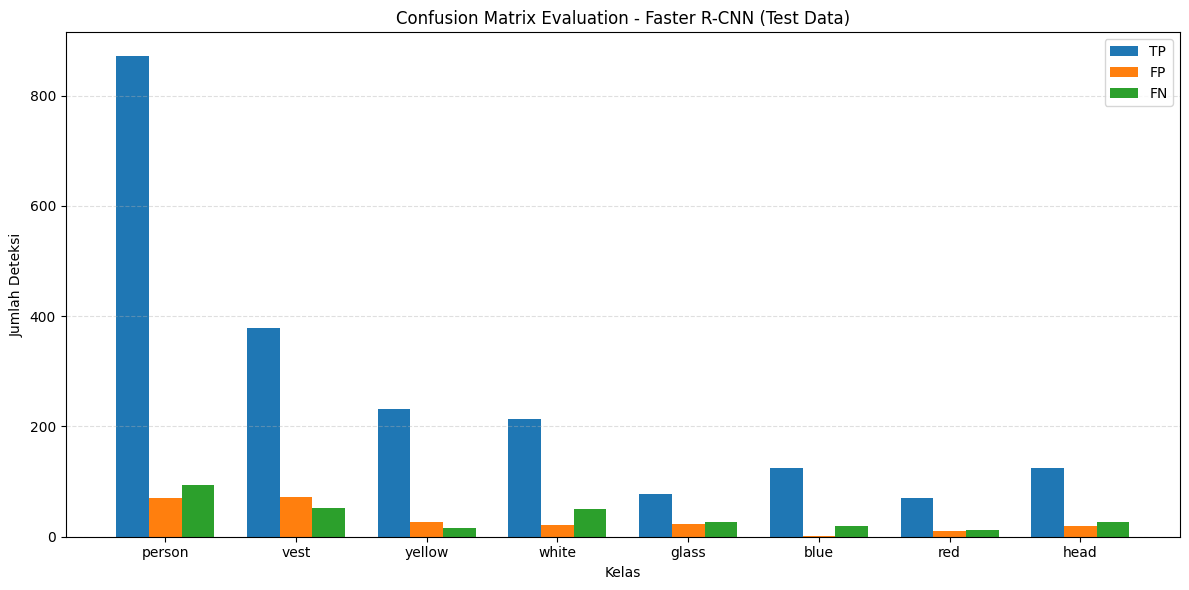

Grafik berhasil disimpan di:
C:\Faster-RCNN-PPE\visualisasi_TP_FP_FN_faster_rcnn_epoch10.png


In [6]:
# Visualisasi TP, FP, FN
import matplotlib.pyplot as plt
import numpy as np

# Mengambil data hasil evaluasi per kelas
class_names = [row["Class"] for row in results_test if row["Class"] != "All"]

tp_values = [row["TP"] for row in results_test if row["Class"] != "All"]
fp_values = [row["FP"] for row in results_test if row["Class"] != "All"]
fn_values = [row["FN"] for row in results_test if row["Class"] != "All"]

# Posisi setiap kelas
x = np.arange(len(class_names))
width = 0.25

# Membuat grafik
plt.figure(figsize=(12, 6))

plt.bar(x - width, tp_values, width, label="TP")
plt.bar(x, fp_values, width, label="FP")
plt.bar(x + width, fn_values, width, label="FN")

plt.xlabel("Kelas")
plt.ylabel("Jumlah Deteksi")
plt.title("Confusion Matrix Evaluation - Faster R-CNN (Test Data)")

plt.xticks(x, class_names)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Menyimpan grafik
output_path = r"C:\Faster-RCNN-PPE\visualisasi_TP_FP_FN_faster_rcnn_epoch10.png"

plt.savefig(output_path, dpi=300, bbox_inches="tight")

# Menampilkan grafik
plt.show()

print("Grafik berhasil disimpan di:")
print(output_path)

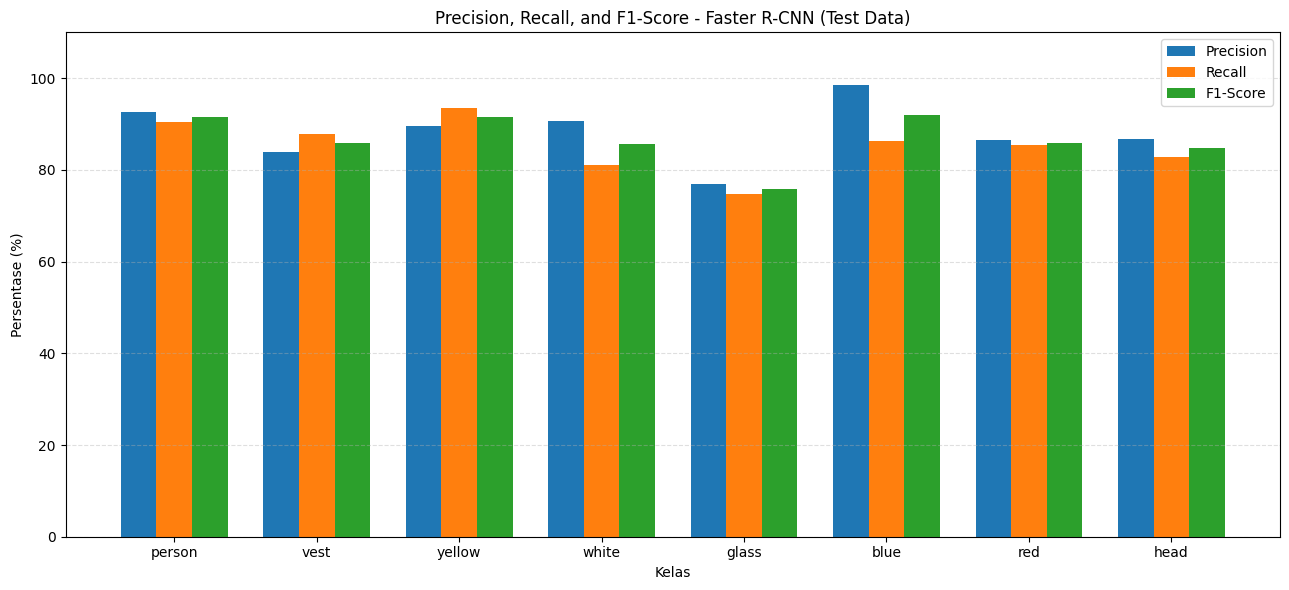

Grafik berhasil disimpan di:
C:\Faster-RCNN-PPE\visualisasi_precision_recall_f1_faster_rcnn_epoch10.png


In [7]:
# Visualisasi Precision, Recall, F1-Score
import matplotlib.pyplot as plt
import numpy as np

# Mengambil data per kelas (tanpa baris All)
class_names = [
    row["Class"] for row in results_test
    if row["Class"] != "All"
]

precision_values = [
    row["Precision"] for row in results_test
    if row["Class"] != "All"
]

recall_values = [
    row["Recall"] for row in results_test
    if row["Class"] != "All"
]

f1_values = [
    row["F1-Score"] for row in results_test
    if row["Class"] != "All"
]

# Posisi setiap kelas
x = np.arange(len(class_names))
width = 0.25

# Membuat grafik
plt.figure(figsize=(13, 6))

plt.bar(x - width, precision_values, width, label="Precision")
plt.bar(x, recall_values, width, label="Recall")
plt.bar(x + width, f1_values, width, label="F1-Score")

plt.xlabel("Kelas")
plt.ylabel("Persentase (%)")
plt.title("Precision, Recall, and F1-Score - Faster R-CNN (Test Data)")

plt.xticks(x, class_names)
plt.ylim(0, 110)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Menyimpan grafik
output_path = r"C:\Faster-RCNN-PPE\visualisasi_precision_recall_f1_faster_rcnn_epoch10.png"

plt.savefig(output_path, dpi=300, bbox_inches="tight")

# Menampilkan grafik
plt.show()

print("Grafik berhasil disimpan di:")
print(output_path)

In [34]:
# Menyimpan confusion matrix
import csv
from pathlib import Path

# Lokasi penyimpanan
output_confusion = Path(
    r"C:\Faster-RCNN-PPE\hasil_pengujian_confusion_faster_rcnn_epoch10.csv"
)

# Menyimpan hasil pengujian
with open(
    output_confusion,
    mode="w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.writer(file, delimiter=";")

    # Header CSV
    writer.writerow([
        "Class",
        "TP",
        "FP",
        "FN",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ])

    # Menulis hasil seluruh kelas dan All
    for row in results_test:

        writer.writerow([
            row["Class"],
            row["TP"],
            row["FP"],
            row["FN"],
            round(row["Precision"], 2),
            round(row["Recall"], 2),
            round(row["F1-Score"], 2)
        ])

print("=== PENYIMPANAN HASIL PENGUJIAN SELESAI ===")
print("Lokasi file :", output_confusion)
print("Nama file   :", output_confusion.name)
print("Jumlah data :", len(results_test))

=== PENYIMPANAN HASIL PENGUJIAN SELESAI ===
Lokasi file : C:\Faster-RCNN-PPE\hasil_pengujian_confusion_faster_rcnn_epoch10.csv
Nama file   : hasil_pengujian_confusion_faster_rcnn_epoch10.csv
Jumlah data : 9


(5) Menghitung mAP per kelas dan keseluruhan
- IoU 0.50 untuk mAP50
- IoU 0.50 sampai 0.95 dengan interval 0.05 untuk mAP50-95
- Confidence minimum 0.001 dari prediksi yang sudah dikumpulkan
- Metode interpolasi 101 titik untuk menghitung AP

In [30]:
# Mengumpulkan prediksi dan ground truth untuk evaluasi mAP

# Simpan konfigurasi model sebelumnya
original_score_thresh = model.roi_heads.score_thresh
original_detections_per_img = model.roi_heads.detections_per_img

# Konfigurasi khusus pengujian mAP
model.roi_heads.score_thresh = 0.001
model.roi_heads.detections_per_img = 100
model.eval()

# Tempat penyimpanan hasil prediksi dan ground truth
map_predictions = []
map_targets = []

print("Mulai mengumpulkan prediksi data test...")

with torch.no_grad():

    for image_idx, (images, targets) in enumerate(test_loader):

        # Inferensi satu gambar
        images = [img.to(device) for img in images]
        predictions = model(images)

        prediction = predictions[0]
        target = targets[0]

        # Simpan prediksi di CPU
        map_predictions.append({
            "image_id": image_idx,
            "boxes": prediction["boxes"].detach().cpu(),
            "labels": prediction["labels"].detach().cpu(),
            "scores": prediction["scores"].detach().cpu()
        })

        # Simpan ground truth di CPU
        map_targets.append({
            "image_id": image_idx,
            "boxes": target["boxes"].detach().cpu(),
            "labels": target["labels"].detach().cpu()
        })

        # Bersihkan variabel gambar
        del predictions, prediction
        del images, targets

        if (image_idx + 1) % 50 == 0:
            print(f"{image_idx + 1}/{len(test_dataset)} gambar selesai")

# Kembalikan konfigurasi model seperti semula
model.roi_heads.score_thresh = original_score_thresh
model.roi_heads.detections_per_img = original_detections_per_img

print("\n=== PENGUMPULAN DATA mAP SELESAI ===")
print("Jumlah gambar       :", len(map_predictions))
print("Jumlah ground truth :", len(map_targets))
print("Confidence minimum  : 0.001")
print("Maksimum deteksi    : 100 per gambar")

Mulai mengumpulkan prediksi data test...
50/340 gambar selesai
100/340 gambar selesai
150/340 gambar selesai
200/340 gambar selesai
250/340 gambar selesai
300/340 gambar selesai

=== PENGUMPULAN DATA mAP SELESAI ===
Jumlah gambar       : 340
Jumlah ground truth : 340
Confidence minimum  : 0.001
Maksimum deteksi    : 100 per gambar


In [31]:
# Menghitung jumlah ground truth setiap kelas
gt_counts = {
    class_id: sum(
        (target["labels"] == class_id).sum().item()
        for target in map_targets
    )
    for class_id in CLASS_NAMES
}

print("=== JUMLAH GROUND TRUTH DATA TEST ===")

for class_id, class_name in CLASS_NAMES.items():
    print(f"{class_name:8s}: {gt_counts[class_id]:5d}")

print("-" * 25)
print(f"{'All':8s}: {sum(gt_counts.values()):5d}")

=== JUMLAH GROUND TRUTH DATA TEST ===
person  :   964
vest    :   430
yellow  :   247
white   :   263
glass   :   103
blue    :   145
red     :    82
head    :   151
-------------------------
All     :  2385


In [32]:
# Menghitung mAP
import numpy as np
from torchvision.ops import box_iou

IOU_THRESHOLDS = np.arange(0.50, 0.96, 0.05)


def calculate_ap(tp_list, fp_list, total_gt):

    if total_gt == 0:
        return 0.0

    tp_cum = np.cumsum(tp_list)
    fp_cum = np.cumsum(fp_list)

    recalls = tp_cum / total_gt
    precisions = tp_cum / (tp_cum + fp_cum)

    # Precision envelope
    precisions = np.maximum.accumulate(
        precisions[::-1]
    )[::-1]

    # Interpolasi 101 titik
    recall_points = np.linspace(0, 1, 101)

    interpolated = [
        np.max(precisions[recalls >= r])
        if np.any(recalls >= r) else 0.0
        for r in recall_points
    ]

    return np.mean(interpolated)


def calculate_ap_class(class_id, iou_threshold):

    total_gt = gt_counts[class_id]

    if total_gt == 0:
        return 0.0

    detections = []

    # Mengumpulkan prediksi seluruh gambar
    for image_idx, prediction in enumerate(map_predictions):

        mask = prediction["labels"] == class_id

        boxes = prediction["boxes"][mask]
        scores = prediction["scores"][mask]

        for box, score in zip(boxes, scores):

            detections.append({
                "image_id": image_idx,
                "box": box,
                "score": score.item()
            })

    # Urutkan confidence tertinggi
    detections.sort(
        key=lambda x: x["score"],
        reverse=True
    )

    matched_gt = {
        i: set() for i in range(len(map_targets))
    }

    tp_list = []
    fp_list = []

    # Matching prediksi dengan ground truth
    for detection in detections:

        image_idx = detection["image_id"]
        target = map_targets[image_idx]

        gt_indices = [
            j for j, label in enumerate(target["labels"].tolist())
            if label == class_id
        ]

        available = [
            j for j in gt_indices
            if j not in matched_gt[image_idx]
        ]

        if not available:
            tp_list.append(0)
            fp_list.append(1)
            continue

        ious = box_iou(
            detection["box"].unsqueeze(0),
            target["boxes"][available]
        )[0]

        best_idx = torch.argmax(ious).item()

        if ious[best_idx].item() >= iou_threshold:

            tp_list.append(1)
            fp_list.append(0)

            matched_gt[image_idx].add(
                available[best_idx]
            )

        else:
            tp_list.append(0)
            fp_list.append(1)

    return calculate_ap(
        tp_list,
        fp_list,
        total_gt
    )


# Menghitung AP setiap kelas
ap_results = []

for class_id, class_name in CLASS_NAMES.items():

    # AP pada IoU 0.50
    ap50 = calculate_ap_class(class_id, 0.50)

    # AP pada IoU 0.50 sampai 0.95
    ap_values = []

    for iou_threshold in IOU_THRESHOLDS:

        ap = calculate_ap_class(
            class_id,
            float(iou_threshold)
        )

        ap_values.append(ap)

    ap50_95 = np.mean(ap_values)

    ap_results.append({
        "Class": class_name,
        "mAP50": ap50 * 100,
        "mAP50-95": ap50_95 * 100
    })


# Menghitung rata-rata seluruh kelas
overall_map50 = np.mean([
    row["mAP50"] for row in ap_results
])

overall_map50_95 = np.mean([
    row["mAP50-95"] for row in ap_results
])


# Menampilkan tabel hasil
print("=" * 65)
print("HASIL EVALUASI mAP FASTER R-CNN")
print("=" * 65)

print(
    f"{'Class':<15}"
    f"{'Images':>10}"
    f"{'Instances':>12}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
)

print("-" * 65)

for row in ap_results:

    class_id = next(
        key for key, value in CLASS_NAMES.items()
        if value == row["Class"]
    )

    print(
        f"{row['Class']:<15}"
        f"{sum(1 for t in map_targets if class_id in t['labels'].tolist()):>10}"
        f"{gt_counts[class_id]:>12}"
        f"{row['mAP50']:>11.3f}%"
        f"{row['mAP50-95']:>13.3f}%"
    )

print("-" * 65)

print(
    f"{'all':<15}"
    f"{len(test_dataset):>10}"
    f"{sum(gt_counts.values()):>12}"
    f"{overall_map50:>11.3f}%"
    f"{overall_map50_95:>13.3f}%"
)

print("=" * 65)

HASIL EVALUASI mAP FASTER R-CNN
Class              Images   Instances       mAP50      mAP50-95
-----------------------------------------------------------------
person                338         964     92.841%       60.084%
vest                  180         430     89.878%       53.874%
yellow                142         247     93.103%       58.274%
white                 120         263     86.570%       51.397%
glass                  76         103     75.166%       41.368%
blue                   73         145     95.501%       60.208%
red                    51          82     89.401%       48.521%
head                   40         151     88.129%       48.457%
-----------------------------------------------------------------
all                   340        2385     88.824%       52.773%


In [33]:
# Menyimpan hasil mAP
import csv
from pathlib import Path

# Lokasi penyimpanan
output_path = Path(
    r"C:\Faster-RCNN-PPE\hasil_pengujian_mAP_faster_rcnn_epoch10.csv"
)

# Menulis hasil ke CSV
with open(output_path, mode="w", newline="", encoding="utf-8-sig") as file:

    writer = csv.writer(file, delimiter=";")

    # Header tabel
    writer.writerow([
        "Class",
        "Images",
        "Instances",
        "mAP50",
        "mAP50-95"
    ])

    # Hasil setiap kelas
    for row in ap_results:

        class_id = next(
            key for key, value in CLASS_NAMES.items()
            if value == row["Class"]
        )

        images_count = sum(
            1 for target in map_targets
            if class_id in target["labels"].tolist()
        )

        writer.writerow([
            row["Class"],
            images_count,
            gt_counts[class_id],
            round(row["mAP50"], 3),
            round(row["mAP50-95"], 3)
        ])

    # Baris keseluruhan
    writer.writerow([
        "all",
        len(test_dataset),
        sum(gt_counts.values()),
        round(overall_map50, 3),
        round(overall_map50_95, 3)
    ])

print("=== PENYIMPANAN HASIL mAP SELESAI ===")
print("Lokasi file :", output_path)
print("Nama file   :", output_path.name)
print("Jumlah data :", len(ap_results) + 1)

=== PENYIMPANAN HASIL mAP SELESAI ===
Lokasi file : C:\Faster-RCNN-PPE\hasil_pengujian_mAP_faster_rcnn_epoch10.csv
Nama file   : hasil_pengujian_mAP_faster_rcnn_epoch10.csv
Jumlah data : 9


(6) Mengukur Kecepatan Deteksi

In [8]:
# Kesiapan model dan dataset
print("Model tersedia      :", "model" in globals())
print("Dataset test tersedia:", "test_dataset" in globals())
print("DataLoader tersedia  :", "test_loader" in globals())
print("Device tersedia      :", "device" in globals())

Model tersedia      : False
Dataset test tersedia: False
DataLoader tersedia  : False
Device tersedia      : False


In [9]:
# Import library & konfigurasi DirectML
from pathlib import Path
import time
import torch
import torch_directml
import xml.etree.ElementTree as ET

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import fasterrcnn_resnet50_fpn

device = torch_directml.device()

print("Device:", device)
print("PyTorch:", torch.__version__)
print("DirectML berhasil diinisialisasi!")

Device: privateuseone:0
PyTorch: 2.4.1+cpu
DirectML berhasil diinisialisasi!


In [10]:
# Memuat kembali data test
ROOT = Path(r"C:\Faster-RCNN-PPE\dataset\images")

CLASS_MAP = {
    "person": 1,
    "vest": 2,
    "yellow": 3,
    "white": 4,
    "glass": 5,
    "blue": 6,
    "red": 7,
    "head": 8
}

class CHVGPpeDataset(Dataset):
    def __init__(self, root, split):
        self.folder = Path(root) / split
        self.images = sorted([
            f for f in self.folder.iterdir()
            if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg"]
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        xml_path = self.folder / (image_path.stem + ".xml")

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        xml_root = ET.parse(xml_path).getroot()

        boxes = []
        labels = []

        for obj in xml_root.findall("object"):
            class_name = obj.findtext("name")

            if class_name not in CLASS_MAP:
                raise ValueError(f"Kelas tidak dikenal: {class_name}")

            bbox = obj.find("bndbox")

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            xmin = max(0, min(xmin, width))
            ymin = max(0, min(ymin, height))
            xmax = max(0, min(xmax, width))
            ymax = max(0, min(ymax, height))

            if xmin >= xmax or ymin >= ymax:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(CLASS_MAP[class_name])

        image_tensor = to_tensor(image)

        boxes_tensor = torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4)

        labels_tensor = torch.tensor(
            labels, dtype=torch.int64
        )

        target = {
            "boxes": boxes_tensor,
            "labels": labels_tensor,
            "image_id": torch.tensor([idx]),
            "area": (
                (boxes_tensor[:, 2] - boxes_tensor[:, 0]) *
                (boxes_tensor[:, 3] - boxes_tensor[:, 1])
            ),
            "iscrowd": torch.zeros(
                (len(labels),), dtype=torch.int64
            )
        }

        return image_tensor, target


test_dataset = CHVGPpeDataset(ROOT, "test")

def collate_fn(batch):
    return tuple(zip(*batch))

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

print("Jumlah gambar test:", len(test_dataset))

Jumlah gambar test: 340


In [11]:
# Memuat epoch 10
model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=9,
    min_size=640,
    max_size=640
)

checkpoint_path = (
    r"C:\Faster-RCNN-PPE\experiments\fasterrcnn_20_epochs"
    r"\fasterrcnn_epoch_10.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

model.to(device)
model.eval()

print("Faster R-CNN epoch 10 berhasil dimuat!")

Faster R-CNN epoch 10 berhasil dimuat!


In [12]:
# Cek kesiapan pengujian
print("Model tersedia       :", "model" in globals())
print("Dataset test tersedia:", "test_dataset" in globals())
print("DataLoader tersedia  :", "test_loader" in globals())
print("Device tersedia      :", "device" in globals())
print("Jumlah gambar test   :", len(test_dataset))

Model tersedia       : True
Dataset test tersedia: True
DataLoader tersedia  : True
Device tersedia      : True
Jumlah gambar test   : 340


In [13]:
# Konfigurasi pengujian kecepatan
TEST_CONF = 0.60
NUM_RUNS = 3

# Mengatur confidence threshold Faster R-CNN
model.roi_heads.score_thresh = 0.001

# Maksimal deteksi per gambar
model.roi_heads.detections_per_img = 100

model.eval()

print("=== KONFIGURASI PENGUJIAN ===")
print("Model              : Faster R-CNN Epoch 10")
print("Dataset            : Test")
print("Jumlah gambar      :", len(test_dataset))
print("Batch size         : 1")
print("Confidence threshold:", TEST_CONF)
print("Pengulangan        :", NUM_RUNS)
print("Device             :", device)

=== KONFIGURASI PENGUJIAN ===
Model              : Faster R-CNN Epoch 10
Dataset            : Test
Jumlah gambar      : 340
Batch size         : 1
Confidence threshold: 0.6
Pengulangan        : 3
Device             : privateuseone:0


In [14]:
# Melakukan warm-up model
# Mengambil satu gambar untuk warm-up
warmup_image, _ = test_dataset[0]

warmup_image = warmup_image.to(device)

model.eval()

with torch.no_grad():
    warmup_output = model([warmup_image])

    # Memastikan hasil prediksi sudah tersedia di CPU
    _ = warmup_output[0]["boxes"].cpu()
    _ = warmup_output[0]["scores"].cpu()
    _ = warmup_output[0]["labels"].cpu()

del warmup_image, warmup_output

print("Warm-up Faster R-CNN selesai!")

Warm-up Faster R-CNN selesai!


In [15]:
# Fungsi pengujian satu pengulangan
import csv
import gc
from pathlib import Path

import numpy as np

OUTPUT_CSV = Path(
    r"C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv"
)

def run_speed_test(run_number):

    preprocess_times = []
    inference_times = []
    postprocess_times = []

    model.eval()

    print(f"\n=== PENGULANGAN {run_number} ===")

    with torch.no_grad():

        for image_idx in range(len(test_dataset)):

            # 1. PREPROCESS
            start_pre = time.perf_counter()

            image, _ = test_dataset[image_idx]
            image = image.to(device)

            preprocess_times.append(
                (time.perf_counter() - start_pre) * 1000
            )

            # 2. INFERENCE
            start_inf = time.perf_counter()

            prediction = model([image])

            # Memindahkan output ke CPU untuk memastikan
            # operasi DirectML sudah selesai
            boxes = prediction[0]["boxes"].detach().cpu()
            scores = prediction[0]["scores"].detach().cpu()
            labels = prediction[0]["labels"].detach().cpu()

            inference_times.append(
                (time.perf_counter() - start_inf) * 1000
            )

            # 3. POSTPROCESS
            start_post = time.perf_counter()

            keep = scores >= TEST_CONF

            boxes = boxes[keep]
            scores = scores[keep]
            labels = labels[keep]

            postprocess_times.append(
                (time.perf_counter() - start_post) * 1000
            )

            del image, prediction
            del boxes, scores, labels, keep

            # Membersihkan memori secara berkala
            if (image_idx + 1) % 50 == 0:
                gc.collect()
                print(
                    f"Progress: {image_idx + 1}/"
                    f"{len(test_dataset)} gambar"
                )

    # Menghitung rata-rata waktu per gambar
    avg_pre = np.mean(preprocess_times)
    avg_inf = np.mean(inference_times)
    avg_post = np.mean(postprocess_times)

    avg_total = avg_pre + avg_inf + avg_post

    # FPS berdasarkan rata-rata total waktu per gambar
    fps = 1000 / avg_total if avg_total > 0 else 0

    result = [
        run_number,
        round(avg_pre, 3),
        round(avg_inf, 3),
        round(avg_post, 3),
        round(avg_total, 3),
        round(fps, 3)
    ]

    # Menyimpan hasil setiap pengulangan
    file_exists = OUTPUT_CSV.exists()

    with open(
        OUTPUT_CSV,
        mode="a",
        newline="",
        encoding="utf-8-sig"
    ) as file:

        writer = csv.writer(file, delimiter=";")

        if not file_exists:
            writer.writerow([
                "Pengulangan",
                "Preprocess (ms)",
                "Inference (ms)",
                "Postprocess (ms)",
                "Total (ms)",
                "FPS"
            ])

        writer.writerow(result)

    gc.collect()

    print("\nHasil Pengulangan", run_number)
    print(f"Preprocess : {avg_pre:.3f} ms")
    print(f"Inference  : {avg_inf:.3f} ms")
    print(f"Postprocess: {avg_post:.3f} ms")
    print(f"Total      : {avg_total:.3f} ms")
    print(f"FPS        : {fps:.3f}")

    print("\nHasil berhasil disimpan ke:", OUTPUT_CSV)

    return result

In [16]:
# Pengujian ke-1
hasil_run_1 = run_speed_test(1)


=== PENGULANGAN 1 ===
Progress: 50/340 gambar
Progress: 100/340 gambar
Progress: 150/340 gambar
Progress: 200/340 gambar
Progress: 250/340 gambar
Progress: 300/340 gambar

Hasil Pengulangan 1
Preprocess : 19.894 ms
Inference  : 671.086 ms
Postprocess: 0.243 ms
Total      : 691.223 ms
FPS        : 1.447

Hasil berhasil disimpan ke: C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv


In [17]:
# Pengujian ke-2
hasil_run_2 = run_speed_test(2)


=== PENGULANGAN 2 ===
Progress: 50/340 gambar
Progress: 100/340 gambar
Progress: 150/340 gambar
Progress: 200/340 gambar
Progress: 250/340 gambar
Progress: 300/340 gambar

Hasil Pengulangan 2
Preprocess : 26.402 ms
Inference  : 726.360 ms
Postprocess: 0.751 ms
Total      : 753.513 ms
FPS        : 1.327

Hasil berhasil disimpan ke: C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv


In [18]:
# Pengujian ke-3
hasil_run_3 = run_speed_test(3)


=== PENGULANGAN 3 ===
Progress: 50/340 gambar
Progress: 100/340 gambar
Progress: 150/340 gambar
Progress: 200/340 gambar
Progress: 250/340 gambar
Progress: 300/340 gambar

Hasil Pengulangan 3
Preprocess : 41.380 ms
Inference  : 665.989 ms
Postprocess: 0.169 ms
Total      : 707.539 ms
FPS        : 1.413

Hasil berhasil disimpan ke: C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv


In [19]:
# Simpan hasil pengujian kecepatan
import csv

hasil_kecepatan = [
    [1, 19.894, 671.086, 0.243, 691.223, 1.447],
    [2, 26.402, 726.360, 0.751, 753.513, 1.327],
    [3, 41.380, 665.989, 0.169, 707.539, 1.413],
]

# Menghitung rata-rata setiap metrik
jumlah_run = len(hasil_kecepatan)

rata_rata = [
    "Rata-rata",
    round(sum(row[1] for row in hasil_kecepatan) / jumlah_run, 3),
    round(sum(row[2] for row in hasil_kecepatan) / jumlah_run, 3),
    round(sum(row[3] for row in hasil_kecepatan) / jumlah_run, 3),
    round(sum(row[4] for row in hasil_kecepatan) / jumlah_run, 3),
    round(sum(row[5] for row in hasil_kecepatan) / jumlah_run, 3),
]

# Simpan hasil ke CSV
output_path = (
    r"C:\Faster-RCNN-PPE"
    r"\hasil_kecepatan_faster_rcnn_epoch10.csv"
)

with open(output_path, "w", newline="", encoding="utf-8-sig") as file:
    writer = csv.writer(file, delimiter=";")

    writer.writerow([
        "Pengulangan",
        "Preprocess (ms)",
        "Inference (ms)",
        "Postprocess (ms)",
        "Total (ms)",
        "FPS"
    ])

    writer.writerows(hasil_kecepatan)
    writer.writerow(rata_rata)

print("=== HASIL PENGUJIAN KECEPATAN ===")
for row in hasil_kecepatan:
    print(row)

print("\nRata-rata:", rata_rata)
print("\nFile berhasil disimpan di:")
print(output_path)

=== HASIL PENGUJIAN KECEPATAN ===
[1, 19.894, 671.086, 0.243, 691.223, 1.447]
[2, 26.402, 726.36, 0.751, 753.513, 1.327]
[3, 41.38, 665.989, 0.169, 707.539, 1.413]

Rata-rata: ['Rata-rata', 29.225, 687.812, 0.388, 717.425, 1.396]

File berhasil disimpan di:
C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv


In [20]:
# tampilkan isi file csv
import csv

file_path = r"C:\Faster-RCNN-PPE\hasil_kecepatan_faster_rcnn_epoch10.csv"

with open(file_path, "r", encoding="utf-8-sig") as file:
    reader = csv.reader(file, delimiter=";")

    for row in reader:
        print(" | ".join(row))

Pengulangan | Preprocess (ms) | Inference (ms) | Postprocess (ms) | Total (ms) | FPS
1 | 19.894 | 671.086 | 0.243 | 691.223 | 1.447
2 | 26.402 | 726.36 | 0.751 | 753.513 | 1.327
3 | 41.38 | 665.989 | 0.169 | 707.539 | 1.413
Rata-rata | 29.225 | 687.812 | 0.388 | 717.425 | 1.396


(7) Mengukur Ukuran Model

In [21]:
from pathlib import Path

# Lokasi file model Faster R-CNN Epoch 10
model_path = Path(
    r"C:\Faster-RCNN-PPE\experiments\fasterrcnn_20_epochs"
    r"\fasterrcnn_epoch_10.pth"
)

# Memastikan file tersedia
if model_path.exists():

    # Mengambil ukuran file dalam byte
    size_bytes = model_path.stat().st_size

    # Konversi ke MB
    size_mb = size_bytes / (1024 * 1024)

    print("=== UKURAN MODEL FASTER R-CNN ===")
    print("Nama file  :", model_path.name)
    print("Ukuran     :", round(size_mb, 2), "MB")
    print("Ukuran byte:", f"{size_bytes:,}", "bytes")

else:
    print("File model tidak ditemukan!")

=== UKURAN MODEL FASTER R-CNN ===
Nama file  : fasterrcnn_epoch_10.pth
Ukuran     : 315.03 MB
Ukuran byte: 330,333,752 bytes
